In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

In [20]:
# Step 2: Load dataset
print("📥 Loading Heart Disease Dataset...")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(url, names=column_names, na_values='?')
print("✅ Dataset loaded successfully!")

# Step 3: Data cleaning and preprocessing
print("🔄 Cleaning and preprocessing data...")

# Display initial info
print(f"📊 Initial data shape: {df.shape}")
print(f"🔍 Missing values:\n{df.isnull().sum()}")

# Handle missing values by dropping rows with NaN
df_clean = df.dropna()

# Create binary target (0 = no disease, 1 = disease)
df_clean['target'] = (df_clean['target'] > 0).astype(int)

print(f"📊 Cleaned data shape: {df_clean.shape}")
print(f"🎯 Target distribution:\n{df_clean['target'].value_counts()}")


📥 Loading Heart Disease Dataset...
✅ Dataset loaded successfully!
🔄 Cleaning and preprocessing data...
📊 Initial data shape: (303, 14)
🔍 Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
📊 Cleaned data shape: (297, 14)
🎯 Target distribution:
target
0    160
1    137
Name: count, dtype: int64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_1388\667396601.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['target'] = (df_clean['target'] > 0).astype(int)


In [21]:
# Step 4: Data exploration
print("\n📋 Dataset overview:")
print(df_clean.head())
print(f"\n📊 Statistical summary:")
print(df_clean.describe())

# Step 5: Prepare features and target
X = df_clean.drop('target', axis=1)
y = df_clean['target']

print(f"\n🎯 Features shape: {X.shape}")
print(f"🎯 Target shape: {y.shape}")

# Step 6: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📊 Training set: {X_train.shape}")
print(f"📊 Test set: {X_test.shape}")


📋 Dataset overview:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

📊 Statistical summary:
              age         sex          cp    trestbps        chol         fbs  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   
std      9.049736    0.468500    0.964859   17.762806   51.997583    

In [22]:
# Step 7: Scale features
print("🔄 Scaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("✅ Feature scaling completed!")

# Step 8: Train multiple classification models
print("\n🤖 Training multiple models...")

models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'XGBoost': XGBClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    print(f"🔄 Training {name}...")
    model.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_pred_proba)
    
    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'auc': auc_score,
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    print(f"✅ {name}: Accuracy = {accuracy:.4f}, AUC = {auc_score:.4f}")

🔄 Scaling features...
✅ Feature scaling completed!

🤖 Training multiple models...
🔄 Training Logistic Regression...
✅ Logistic Regression: Accuracy = 0.8333, AUC = 0.9498
🔄 Training Random Forest...
✅ Random Forest: Accuracy = 0.8667, AUC = 0.9414
🔄 Training SVM...
✅ SVM: Accuracy = 0.8500, AUC = 0.9542
🔄 Training XGBoost...
✅ XGBoost: Accuracy = 0.8667, AUC = 0.8917


In [23]:
# Step 9: Find and evaluate best model
best_model_name = max(results, key=lambda x: results[x]['accuracy'])
best_model = results[best_model_name]['model']

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"🎯 Best Accuracy: {results[best_model_name]['accuracy']:.4f}")

# Detailed evaluation of best model
y_pred_best = results[best_model_name]['predictions']
y_pred_proba_best = results[best_model_name]['probabilities']

print("\n📊 Detailed Classification Report:")
print(classification_report(y_test, y_pred_best))



🏆 BEST MODEL: Random Forest
🎯 Best Accuracy: 0.8667

📊 Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60



📈 Creating visualizations...


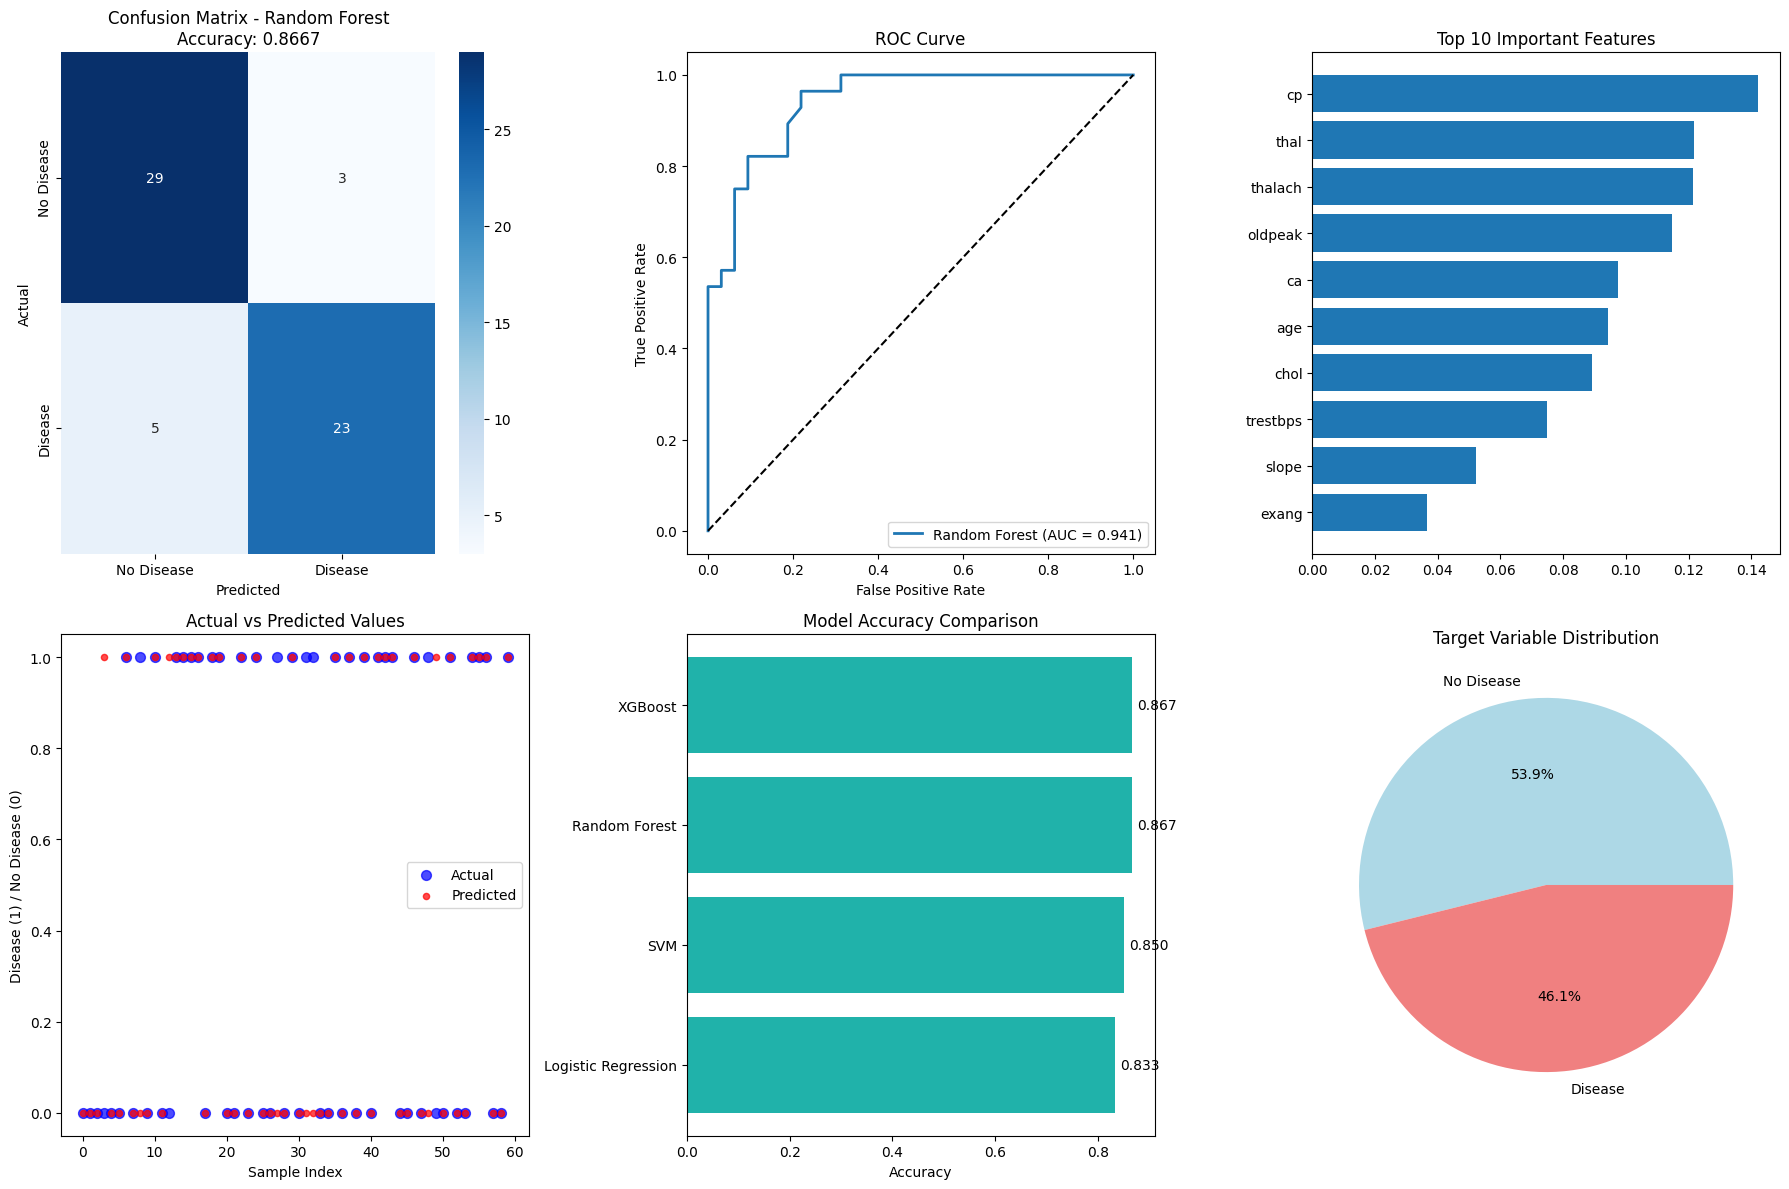

In [24]:
# Step 10: Visualizations
print("📈 Creating visualizations...")
plt.figure(figsize=(18, 12))

# Plot 1: Confusion Matrix
plt.subplot(2, 3, 1)
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.title(f'Confusion Matrix - {best_model_name}\nAccuracy: {results[best_model_name]["accuracy"]:.4f}')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Plot 2: ROC Curve
plt.subplot(2, 3, 2)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_best)
plt.plot(fpr, tpr, linewidth=2, label=f'{best_model_name} (AUC = {results[best_model_name]["auc"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()


# Plot 3: Feature Importance (if available)
plt.subplot(2, 3, 3)
if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=True)
    
    plt.barh(feature_importance['feature'][-10:], feature_importance['importance'][-10:])
    plt.title('Top 10 Important Features')
else:
    # Show model comparison instead
    model_names = list(results.keys())
    accuracies = [results[name]['accuracy'] for name in model_names]
    plt.barh(model_names, accuracies, color=['skyblue', 'lightgreen', 'lightcoral', 'gold'])
    plt.title('Model Comparison - Accuracy')
    plt.xlabel('Accuracy')

# Plot 4: Actual vs Predicted
plt.subplot(2, 3, 4)
plt.scatter(range(len(y_test)), y_test, alpha=0.7, label='Actual', s=50, color='blue')
plt.scatter(range(len(y_pred_best)), y_pred_best, alpha=0.7, label='Predicted', s=20, color='red')
plt.title('Actual vs Predicted Values')
plt.xlabel('Sample Index')
plt.ylabel('Disease (1) / No Disease (0)')
plt.legend()

# Plot 5: Model Accuracy Comparison
plt.subplot(2, 3, 5)
models_comparison = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'AUC': [results[name]['auc'] for name in results.keys()]
}).sort_values('Accuracy', ascending=True)

plt.barh(models_comparison['Model'], models_comparison['Accuracy'], color='lightseagreen')
plt.title('Model Accuracy Comparison')
plt.xlabel('Accuracy')
for i, v in enumerate(models_comparison['Accuracy']):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center')


# Plot 6: Target Distribution
plt.subplot(2, 3, 6)
target_counts = df_clean['target'].value_counts()
colors = ['lightblue', 'lightcoral']
plt.pie(target_counts.values, labels=['No Disease', 'Disease'], autopct='%1.1f%%', colors=colors)
plt.title('Target Variable Distribution')

plt.tight_layout()
plt.show()

In [25]:
# Step 11: Sample predictions
print("\n🔍 Sample Predictions:")
print("=" * 50)

for i in range(5):
    sample_features = X_test_scaled[i].reshape(1, -1)
    actual = y_test.iloc[i] if hasattr(y_test, 'iloc') else y_test[i]
    predicted = best_model.predict(sample_features)[0]
    probability = best_model.predict_proba(sample_features)[0][1]
    
    print(f"Sample {i+1}:")
    print(f"  Actual: {'Disease' if actual == 1 else 'No Disease'} ({actual})")
    print(f"  Predicted: {'Disease' if predicted == 1 else 'No Disease'} ({predicted})")
    print(f"  Disease Probability: {probability:.4f}")
    print(f"  Result: {'✅ CORRECT' if actual == predicted else '❌ WRONG'}")
    print("-" * 30)


🔍 Sample Predictions:
Sample 1:
  Actual: No Disease (0)
  Predicted: No Disease (0)
  Disease Probability: 0.0300
  Result: ✅ CORRECT
------------------------------
Sample 2:
  Actual: No Disease (0)
  Predicted: No Disease (0)
  Disease Probability: 0.1300
  Result: ✅ CORRECT
------------------------------
Sample 3:
  Actual: No Disease (0)
  Predicted: No Disease (0)
  Disease Probability: 0.4500
  Result: ✅ CORRECT
------------------------------
Sample 4:
  Actual: No Disease (0)
  Predicted: Disease (1)
  Disease Probability: 0.6800
  Result: ❌ WRONG
------------------------------
Sample 5:
  Actual: No Disease (0)
  Predicted: No Disease (0)
  Disease Probability: 0.3500
  Result: ✅ CORRECT
------------------------------


In [26]:
# Step 12: Final summary
print("\n" + "="*60)
print("🎉 TASK 4 COMPLETED SUCCESSFULLY!")
print("="*60)
print(f"📊 Dataset: Heart Disease (Cleveland)")
print(f"🏆 Best Model: {best_model_name}")
print(f"🎯 Best Accuracy: {results[best_model_name]['accuracy']:.4f}")
print(f"📈 Best AUC Score: {results[best_model_name]['auc']:.4f}")
print(f"🔢 Total Samples: {df_clean.shape[0]}")
print(f"🎯 Features Used: {X.shape[1]}")
print("="*60)


🎉 TASK 4 COMPLETED SUCCESSFULLY!
📊 Dataset: Heart Disease (Cleveland)
🏆 Best Model: Random Forest
🎯 Best Accuracy: 0.8667
📈 Best AUC Score: 0.9414
🔢 Total Samples: 297
🎯 Features Used: 13


# Thank you